In [ ]:
# script for downloading NASA GEX-NDDP data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

import os
import warnings
warnings.filterwarnings('ignore')
from urllib.parse import urlencode, urljoin
from urllib.request import urlopen

from cartopy import crs as ccrs, feature as cfeature
import netCDF4
from netCDF4 import Dataset
from datetime import datetime as dt
import xarray as xr

## Change path to correct data directory

In [2]:
! pwd

/Users/tedscott/Google Drive/My Drive/PhD Work/Codes/HeatWaves/HeatWaves


In [2]:
# example URL: https://ds.nccs.nasa.gov/thredds/fileServer/AMES/NEX/GDDP-CMIP6/CESM2/historical/r4i1p1f1/tas/tas_day_CESM2_historical_r4i1p1f1_gn_1962_v2.0.nc
os.chdir('../../../Data/CMIP6/NEX-GDDP-CMIP6/FGOALS-g3/raw')
! ls -al

total 66359168
drwxr-xr-x@ 142 tedscott  staff       4544 Oct 14 06:36 .
drwxr-xr-x@   5 tedscott  staff        160 Oct 13 08:05 ..
-rw-r--r--@   1 tedscott  staff  242840636 Oct 13 08:13 tas_day_FGOALS-g3_historical_r3i1p1f1_gn_1961_v2.0.nc
-rw-r--r--@   1 tedscott  staff  242820575 Oct 13 08:22 tas_day_FGOALS-g3_historical_r3i1p1f1_gn_1962_v2.0.nc
-rw-r--r--@   1 tedscott  staff  242898076 Oct 13 08:31 tas_day_FGOALS-g3_historical_r3i1p1f1_gn_1963_v2.0.nc
-rw-r--r--@   1 tedscott  staff  242853995 Oct 13 08:41 tas_day_FGOALS-g3_historical_r3i1p1f1_gn_1964_v2.0.nc
-rw-r--r--@   1 tedscott  staff  242852154 Oct 13 08:50 tas_day_FGOALS-g3_historical_r3i1p1f1_gn_1965_v2.0.nc
-rw-r--r--@   1 tedscott  staff  242910730 Oct 13 08:59 tas_day_FGOALS-g3_historical_r3i1p1f1_gn_1966_v2.0.nc
-rw-r--r--@   1 tedscott  staff  242879425 Oct 13 09:08 tas_day_FGOALS-g3_historical_r3i1p1f1_gn_1967_v2.0.nc
-rw-r--r--@   1 tedscott  staff  242912383 Oct 13 09:17 tas_day_FGOALS-g3_historical_r3i1p1f1_gn_1

## Download files

In [7]:
# try downloading to local drive to see if this is faster?
#os.chdir('/Users/tedscott/Downloads/CMIP6-downloads/')

In [12]:
process_yrs = np.arange(2085,2101,1)
#process_yrs = [2016]
process_yrs

array([2085, 2086, 2087, 2088, 2089, 2090, 2091, 2092, 2093, 2094, 2095,
       2096, 2097, 2098, 2099, 2100])

In [ ]:
%%time
# taking roughly 9 min per file on 2026-10-06
# help from https://realpython.com/python-download-file-from-url/#downloading-a-large-file-in-a-streaming-fashion

scenario = "ssp370"#"historical"#"ssp245"
realization = "r3i1p1f1"#"r4i1p1f1"
model = "FGOALS-g3"#"CanESM5"#"CESM2"
grid = "gn"#"gr1"#"gn"

for yr in process_yrs:

    start = dt.now()
    
    filename = "tas_day_"+model+"_"+scenario+"_"+realization+"_"+grid+"_"+str(yr)+"_v2.0.nc"
    url = "https://ds.nccs.nasa.gov/thredds/fileServer/AMES/NEX/GDDP-CMIP6/"+model+"/"+scenario+"/"+realization+"/tas/"+filename
    response = requests.get(url, stream=True)
    response.headers

    with open(filename, mode="wb") as file:
        for chunk in response.iter_content():
            file.write(chunk)
            
    end = dt.now()
    elapsed = (end-start).total_seconds()/60.0
    print("Time for "+str(yr)+" :"+str(elapsed)+" min")


## Use CDO to regrid to match ERA5 and fix time variable

### using os.system() calls to cdo

In [30]:
process_yrs = np.arange(2015,2101,1)
#scenario = "historical"

In [ ]:
%%time

# 12 min per year

for yr in process_yrs:
    start = dt.now()

    # change grid to match ERA5
    cmd = "remapbil,r1440x721"
    infile = "tas_day_"+model+"_"+scenario+"_"+realization+"_"+grid+"_"+str(yr)+"_v2.0.nc"
    outfile = "../regridded/tas_day_"+model+"_"+scenario+"_"+realization+"_"+grid+"_"+str(yr)+"_v2.0.nc"
    os.system("cdo "+cmd+" "+infile+" "+outfile)

    # set longitude range
    cmd2 = "-sellonlatbox,-180,180,-90,90"
    infile2 = "../regridded/tas_day_"+model+"_"+scenario+"_"+realization+"_"+grid+"_"+str(yr)+"_v2.0.nc"
    outfile2 = "../regridded/tas_day_"+model+"_"+scenario+"_"+str(yr)+"_1440x721.nc"
    os.system("cdo "+cmd2+" "+infile2+" "+outfile2)

    # fix time variable
    ds_model = xr.open_mfdataset(outfile2)
    ds_model['time'] = ds_model.indexes['time'].to_datetimeindex() # ACCESS-ESM1-5 is already datetime64?

    # output final version
    outpath = "../regridded/tas_"+model+"_"+scenario+"_"+str(yr)+".nc"

    # include some compression to reduce file size on disk
    comp = dict(zlib=True, complevel=5)
    encoding = {var: comp for var in ds_model.data_vars}
    ds_model.to_netcdf(outpath, encoding=encoding)
    
    # remove intermediate files
    os.system("rm "+outfile)
    os.system("rm "+outfile2)

    end = dt.now()
    elapsed = (end-start).total_seconds()/60.0
    print("Time for "+str(yr)+" :"+str(elapsed)+" min")

In [32]:
ds_model

<xarray.Dataset> Size: 2GB
Dimensions:  (time: 365, lat: 721, lon: 1440)
Coordinates:
  * time     (time) datetime64[ns] 3kB 2100-01-01T12:00:00 ... 2100-12-31T12:...
  * lat      (lat) float64 6kB -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
  * lon      (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
Data variables:
    tas      (time, lat, lon) float32 2GB dask.array<chunksize=(1, 721, 1440), meta=np.ndarray>
Attributes: (12/25)
    CDI:                   Climate Data Interface version 2.5.0 (https://mpim...
    Conventions:           CF-1.7
    source:                BCSD
    institution:           NASA Earth Exchange, NASA Ames Research Center, Mo...
    cmip6_source_id:       BCC-CSM2-MR
    cmip6_institution_id:  BCC
    ...                    ...
    contact:               Dr. Bridget Thrasher: bridget@climateanalyticsgrou...
    creation_date:         Sat Nov 16 20:16:24 PST 2024
    disclaimer:            These data are considered provisional and subject ...
    tracking_id:           c70df4ee-3830-41ee-9d34-83267e660280
    history:               Wed Oct 28 06:49:40 2026: cdo -sellonlatbox,-180,1...
    CDO:                   Climate Data Operators version 2.5.0 (https://mpim...

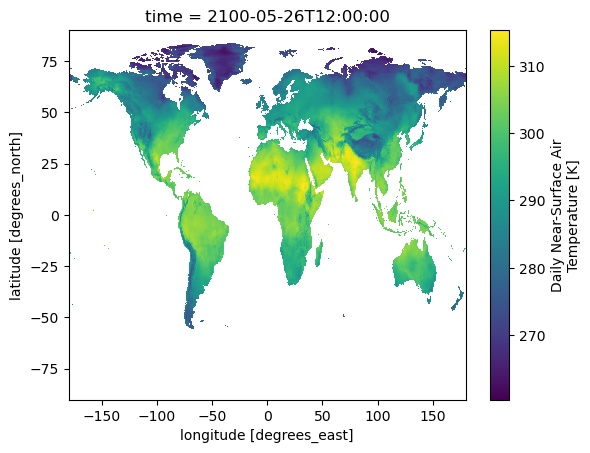

In [33]:
ds_model.tas.sel(time="2100-05-26").plot()